## Лабораторная работа № 1
### Часть 2. Разведочный анализ Delivery ETA

Объект наблюдения — потенциальный заказ в сервисе онлайн-доставки продуктов. Целевая переменная `delivery_eta_minutes` — время прибытия курьера в минутах.

Выполним пункты задания: определим типы признаков, исследуем и устраним пропуски и выбросы, рассчитаем статистики, построим распределения важных признаков и корреляции.

Данные читаются из таблицы Iceberg, созданной первой частью. Исходный файл загружается в HDFS **отдельно в терминале сервера** командой `hdfs dfs -copyFromLocal`, описанной в первой части. Этот ноутбук ничего не копирует.

Ячейки выполняются сверху вниз на сервере с Spark 3.5 / Scala 2.12 и YARN. Расчёты выполняются на всей таблице; для графиков на драйвер передаются только ограниченные сводки. Код намеренно использует отдельные фильтры и подсчёты, поэтому на большом датасете потребуется время.


### 1. Подключение библиотек и Spark
Используем функции PySpark для расчётов и Matplotlib для графиков. Обучение моделей в эту часть работы не входит.


In [222]:
import os  # Имя пользователя сервера.
import math  # Проверка, что результат корреляции — конечное число.
import pandas as pd
from pyspark import SparkConf  # Настройки Spark.
from pyspark.sql import SparkSession, DataFrame
from pyspark.sql import functions as F  # Функции для столбцов.
import matplotlib.pyplot as plt  # Построение графиков.


In [175]:
# База и входная таблица должны совпадать с первой частью.
user_name = os.getenv("USER")

# Адрес датасета, заранее загруженного в HDFS.
path = f"hdfs:///user/{user_name}/datasets/delivery_eta.parquet"

# Имена базы и таблицы для подготовленных данных.

database_name = "delivery_eta_database"
table_name = "sobd_lab1_delivery_eta"
full_table_name = f"spark_catalog.{database_name}.{table_name}"

""" const """
count_col = 10
count_row = 5

In [176]:
def create_spark_configuration() -> SparkConf:
    
    conf = SparkConf()
    conf.setAppName("lab 1 Delivery ETA")
   
    conf.setMaster("yarn")
    conf.set("spark.submit.deployMode", "client")
    conf.set("spark.executor.memory", "12g")
    # Каждому исполнителю выделяем 8 процессорных ядер.
    conf.set("spark.executor.cores", "8") # исполнителю - 8 ядер
    conf.set("spark.executor.instances", "2") #по 2 сущности исполнителя
    conf.set("spark.driver.memory", "4g")
    conf.set("spark.driver.cores", "2")
    
    conf.set("spark.jars.packages", "org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.0")
    conf.set("spark.sql.extensions", "org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions")
    conf.set("spark.sql.catalog.spark_catalog", "org.apache.iceberg.spark.SparkCatalog")
    conf.set("spark.sql.catalog.spark_catalog.type", "hadoop")
    conf.set("spark.sql.catalog.spark_catalog.warehouse", f"hdfs:///user/{user_name}/warehouse")
    conf.set("spark.sql.catalog.spark_catalog.io-impl", "org.apache.iceberg.hadoop.HadoopFileIO")
    return conf

conf = create_spark_configuration()

In [177]:
spark = SparkSession.builder.config(conf=conf).getOrCreate()
spark

### Читаем Базу

In [179]:
df = spark.table(full_table_name)
df.printSchema()

root
 |-- num_0: float (nullable = true)
 |-- num_1: float (nullable = true)
 |-- num_2: float (nullable = true)
 |-- num_3: float (nullable = true)
 |-- num_4: float (nullable = true)
 |-- num_5: float (nullable = true)
 |-- num_6: float (nullable = true)
 |-- num_7: float (nullable = true)
 |-- num_8: float (nullable = true)
 |-- num_9: float (nullable = true)
 |-- bin_0: boolean (nullable = true)
 |-- cat_0: long (nullable = true)
 |-- cat_1: long (nullable = true)
 |-- timestamp: timestamp_ntz (nullable = true)
 |-- delivery_eta_minutes: float (nullable = true)



Фильтруем

In [ ]:
from collections import defaultdict

BIN = "bin"
NUM = "num"
CAT = "cat"

def filrer_df(dataFrame: DataFrame)-> tuple[DataFrame, defaultdict[str, list[str]]]:
    names: defaultdict[str, list[str]] = defaultdict(list[str]) 
    for col in dataFrame.columns:
        if col.startswith("num_"):
            key = NUM
        elif col.startswith("bin_"):
            key = BIN
        elif col.startswith("cat_"):
            key = CAT
        else:
            key = "other"
        names[key].append(col)
        
    return dataFrame, names

In [182]:
df, cols = filrer_df(df, count_col=count_col)

for key, value in cols.items():
    print(f"key: {key}, value: {len(value)}")

df.limit(count_row).toPandas().head(count_row)

key: num, value: 10
key: bin, value: 1
key: cat, value: 2
key: other, value: 2


,num_0,num_1,num_2,num_3,num_4,num_5,num_6,num_7,num_8,num_9,bin_0,cat_0,cat_1,timestamp,delivery_eta_minutes
0,0.485069,0.702299,0.396108,-0.040157,0.499188,0.722666,0.395186,0.060138,1.297110,1.736929,True,174,179,2023-11-14 16:48:04,5.616667
1,-0.750224,-0.538947,-0.620085,-0.234219,-0.782829,-0.600270,-0.643116,-0.134432,0.608535,0.523833,True,371,390,2023-12-27 17:25:36,7.216667
2,-1.166093,-0.317650,0.046436,-0.058999,-1.112750,-0.319044,0.002114,-0.163609,1.944071,1.427953,True,302,315,2023-12-04 09:18:43,13.883333
3,-0.847356,-0.254902,-0.019656,-0.681594,-0.871266,-0.262220,-0.052904,-0.677444,-0.678064,0.669832,True,50,391,2023-12-14 15:03:36,10.883333
4,0.356159,0.560348,0.252311,-0.299230,0.393422,0.594086,0.299042,-0.219060,0.319795,-1.409527,True,394,415,2023-12-26 12:38:45,11.600000


### Снова смотрим Null
а так же дубликаты

In [183]:
print("row dup:", df.count() - df.distinct().count())
sum_num = [F.sum(F.col(c).isNull().cast("int")).alias(f"{c}__null") for c in df.columns]
df.select(*sum_num).toPandas().T.rename(columns={0:"Nulls"}).head(len(sum_num))

row dup: 0


,Nulls
num_0__null,0
num_1__null,0
num_2__null,0
num_3__null,0
num_4__null,0
num_5__null,0
num_6__null,0
num_7__null,0
num_8__null,0
num_9__null,0


### Разбор `delivery_eta_minutes`

In [184]:
DEM = "delivery_eta_minutes"

In [186]:
stats = df.select(
    F.expr(f"percentile_approx({DEM}, 0.01)").alias("p01"),
    F.expr(f"percentile_approx({DEM}, 0.99)").alias("p99"),
).first()

p01, p99 = stats["p01"], stats["p99"]

check = df.select(
    F.count(DEM).alias("count"),
    F.mean(DEM).alias("mean"),
    F.stddev(DEM).alias("std"),
    F.min(DEM).alias("min"),
    F.lit(p01).alias("p01"),
    F.expr(f"percentile_approx({DEM}, 0.25)").alias("p25"),
    F.expr(f"percentile_approx({DEM}, 0.50)").alias("p50"),
    F.expr(f"percentile_approx({DEM}, 0.75)").alias("p75"),
    F.lit(p99).alias("p99"),
    F.max(DEM).alias("max"),
    F.skewness(DEM).alias("skew"),
    F.kurtosis(DEM).alias("kurt"),
    F.sum(F.when(F.col(DEM) < p01, 1).otherwise(0)).alias("lt_p01"),
    F.sum(F.when(F.col(DEM) > p99, 1).otherwise(0)).alias("gt_p99"),
)
check.toPandas().T.rename(columns={0:"property"}).head(len(check.columns))

,property
count,500000.000000
mean,7.531812
std,6.246122
min,0.000000
p01,0.400000
p25,3.333333
p50,5.433333
p75,9.733334
p99,29.516666
max,147.733337


In [187]:
from pyspark.sql import Column

def draw_distribution(c: Column, df: DataFrame):
    STEP = 0.25
    count_bucket = F.floor(c / STEP).cast("int").alias("bucket")

    hist_pd = (
        df
        .select(count_bucket)
        .groupBy("bucket")
        .count()
        .orderBy("bucket")
        .toPandas()
    )
    hist_pd["x"] = hist_pd["bucket"] * STEP

    print("бакетов:", len(hist_pd))
    print("мин bucket:", hist_pd["bucket"].min())
    print("макс bucket:", hist_pd["bucket"].max())  

    _name = c._jc.toString()
    plt.figure(figsize=(12, 5))
    plt.bar(hist_pd["x"], hist_pd["count"], width=STEP * 0.95, align="edge")
    plt.xlabel(_name)
    plt.ylabel("кол-во")
    plt.title(f"Распределение {_name}")
    plt.tight_layout()
    plt.show()

бакетов: 270
мин bucket: 0
макс bucket: 590


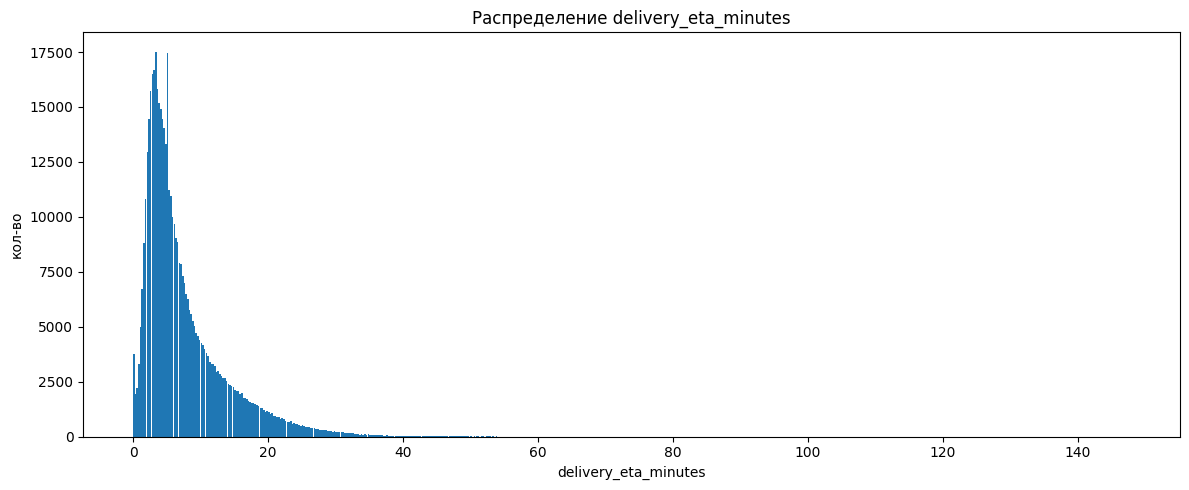

In [188]:
draw_distribution(F.col(DEM), df)

### Показатаели `Num` 

In [189]:
num_s = cols[NUM]

stats = df.select(
    *[F.mean(c).alias(f"{c}_mean") for c in num_s],
    *[F.min(c).alias(f"{c}_min") for c in num_s],
    *[F.max(c).alias(f"{c}_max") for c in num_s],
    *[F.skewness(c).alias(f"{c}_skew") for c in num_s],
    *[F.kurtosis(c).alias(f"{c}_kurt") for c in num_s],
    *[F.stddev(c).alias(f"{c}_stddev") for c in num_s],
)

pd_df = stats.toPandas()

In [190]:
index=("mean", "min", "max", "skew", "kurt", "stddev",)

view_df = pd.DataFrame(index=index)
for c in num_s:
    col = [f"{c}_{pr}" for pr in view_df.index]
    view_df[c] = pd_df[col].T.squeeze().values

view_df.head(len(view_df.index))

,num_0,num_1,num_2,num_3,num_4,num_5,num_6,num_7,num_8,num_9
mean,0.000166,-0.003572,-0.004011,0.009654,0.001533,-0.005143,-0.002278,0.010043,-0.004197,0.003981
min,-4.845584,-4.741838,-4.627289,-3.089935,-4.134903,-3.860776,-5.199337,-5.089130,-3.212438,-3.142850
max,4.648853,4.265921,4.585457,5.199337,5.199337,5.199337,4.076813,4.432878,3.838361,4.750758
skew,-0.014295,0.000255,0.015792,0.037829,-0.009862,-0.000237,0.005382,-0.007830,0.006997,0.018312
kurt,0.152893,0.111762,0.191116,0.254216,-0.041829,-0.058746,-0.050586,-0.019563,-0.092735,-0.047164
stddev,1.010747,1.010376,1.009643,1.008367,1.005532,1.007301,1.003109,1.001534,0.995317,0.999566


выбросы по IQR по Num

In [193]:
num = cols[NUM]

ТУТ Я УЖЕ ПОТЕРЯЛСЯ!!!!

Quantile для num

In [197]:
qs = df.approxQuantile(num, [0.25, 0.75], 0.001)

In [198]:
bounds = []
for c, (q1, q3) in zip(num, qs):
    iqr = q3 - q1
    low  = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    bounds.append({"col": c, "q1": q1, "q3": q3, "iqr": iqr, "low": low, "high": high})

bounds_df = pd.DataFrame(bounds)
bounds_df.head(10).round(4)

,col,q1,q3,iqr,low,high
0,num_0,-0.6742,0.6832,1.3573,-2.7101,2.7192
1,num_1,-0.6850,0.6748,1.3597,-2.7246,2.7144
2,num_2,-0.6911,0.6753,1.3664,-2.7407,2.7249
3,num_3,-0.6659,0.6848,1.3506,-2.6918,2.7107
4,num_4,-0.6750,0.6818,1.3568,-2.7103,2.7170
5,num_5,-0.6899,0.6764,1.3663,-2.7394,2.7259
6,num_6,-0.6872,0.6762,1.3634,-2.7323,2.7213
7,num_7,-0.6657,0.6818,1.3474,-2.6868,2.7029
8,num_8,-0.6823,0.6704,1.3527,-2.7113,2.6994
9,num_9,-0.6743,0.6760,1.3503,-2.6997,2.7015


In [201]:
outlier_exprs = []
for row in bounds:
    c, low, high = row["col"], row["low"], row["high"]
    outlier_exprs.append(
        F.sum(((F.col(c) < low) | (F.col(c) > high)).cast("int")).alias(f"{c}__n_out")
    )


n_out_row = df.select(*outlier_exprs).toPandas().T.rename(columns={0: "value"})
n_out_row.head(len(n_out_row))


,value
num_0__n_out,3687
num_1__n_out,3542
num_2__n_out,3542
num_3__n_out,4350
num_4__n_out,3450
num_5__n_out,3355
num_6__n_out,3340
num_7__n_out,3587
num_8__n_out,3052
num_9__n_out,3092


Дубликаты `num`

In [202]:
cond1 = F.col("num_1").eqNullSafe(F.col("num_2"))
print(df.count())

pairs = {
    "num_1 == num_2": cond1,
}

df.select(*[
    F.sum(expr.cast("int")).alias(name) 
    for name, expr in pairs.items()
]).toPandas().T.rename(columns={0: "duplicate"}).head(len(pairs))

500000


,duplicate
num_1 == num_1,3826


In [207]:
# 1. Разворачиваем n_out_row в удобный вид
n_out_df = n_out_row.reset_index().rename(columns={"index": "col_key", "value": "n_out"})
n_out_df["col"] = n_out_df["col_key"].str.replace("__n_out", "", regex=False)
n_out_df = n_out_df[["col", "n_out"]]

# 2. Мержим с bounds_df
bounds_df = pd.DataFrame(bounds).merge(n_out_df, on="col")
bounds_df["pct"] = bounds_df["n_out"] / df.count() * 100
bounds_df = bounds_df.sort_values("pct", ascending=False).reset_index(drop=True)

bounds_df[["col", "q1", "q3", "low", "high", "n_out", "pct"]].head(len(bounds_df))

,col,q1,q3,low,high,n_out,pct
0,num_3,-0.665852,0.684763,-2.691775,2.710686,4350,0.8700
1,num_0,-0.674152,0.683169,-2.710135,2.719151,3687,0.7374
2,num_7,-0.665682,0.681761,-2.686846,2.702925,3587,0.7174
3,num_1,-0.684990,0.674752,-2.724602,2.714365,3542,0.7084
4,num_2,-0.691121,0.675278,-2.740719,2.724875,3542,0.7084
5,num_4,-0.675046,0.681787,-2.710294,2.717036,3450,0.6900
6,num_5,-0.689918,0.676403,-2.739400,2.725885,3355,0.6710
7,num_6,-0.687216,0.676195,-2.732333,2.721312,3340,0.6680
8,num_9,-0.674292,0.676006,-2.699740,2.701454,3092,0.6184
9,num_8,-0.682317,0.670354,-2.711324,2.699361,3052,0.6104


In [208]:
group_keep     = bounds_df[bounds_df["pct"] <= 1.0]
group_winsor   = bounds_df[(bounds_df["pct"] > 1.0) & (bounds_df["pct"] <= 5.0)]
group_no_touch = bounds_df[bounds_df["pct"] > 5.0]

print(f"≤ 1% выбросов:  {len(group_keep):>3} колонок — оставляем")
print(f"1–5% выбросов:  {len(group_winsor):>3} колонок — винзоризация")
print(f"> 5% выбросов:  {len(group_no_touch):>3} колонок — не трогаем")
print(f"\npct: min={bounds_df['pct'].min():.3f}%, max={bounds_df['pct'].max():.3f}%, mean={bounds_df['pct'].mean():.3f}%")

≤ 1% выбросов:   10 колонок — оставляем
1–5% выбросов:    0 колонок — винзоризация
> 5% выбросов:    0 колонок — не трогаем

pct: min=0.610%, max=0.870%, mean=0.700%


In [210]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation

cols_for_corr = num_s + [DEM]

vec = VectorAssembler(inputCols=cols_for_corr, outputCol="v").transform(df).select("v")

In [215]:
pearson = pd.DataFrame(
    Correlation.corr(vec, "v", "pearson").head()[0].toArray(),
    index=cols_for_corr, columns=cols_for_corr
)
pearson[DEM].drop(DEM).sort_values(key=abs, ascending=False).round(4).head(len(pearson))

num_8    0.4620
num_3    0.0627
num_7    0.0623
num_4    0.0380
num_0    0.0373
num_5    0.0121
num_1    0.0117
num_2    0.0107
num_6    0.0104
num_9    0.0006
Name: delivery_eta_minutes, dtype: float64

In [216]:
spearman = pd.DataFrame(
    Correlation.corr(vec, "v", "spearman").head()[0].toArray(),
    index=cols_for_corr, columns=cols_for_corr
)
spearman[DEM].drop(DEM).sort_values(key=abs, ascending=False).round(4).head(len(spearman))

num_8    0.6106
num_3    0.0993
num_7    0.0987
num_4    0.0526
num_0    0.0520
num_6    0.0095
num_2    0.0092
num_5    0.0089
num_1    0.0081
num_9   -0.0017
Name: delivery_eta_minutes, dtype: float64

In [217]:
c = pearson.drop(DEM, axis=0).drop(DEM, axis=1).abs()

pairs = [(i, j, round(c.loc[i,j], 3))
         for i in c.index for j in c.columns
         if i < j and c.loc[i,j] > 0.9]

print(f"Пар с |corr| > 0.9: {len(pairs)}")
for i, j, v in pairs:
    print(f"  {i} ~ {j}: {v}")

# дополнительно: топ пар с |corr| > 0.7 (не только дубликаты)
print("\nПары с |corr| > 0.7:")
pairs_07 = [(i, j, round(c.loc[i,j], 3))
            for i in c.index for j in c.columns
            if i < j and 0.7 < c.loc[i,j] <= 0.9]
for i, j, v in pairs_07:
    print(f"  {i} ~ {j}: {v}")

Пар с |corr| > 0.9: 8
  num_0 ~ num_4: 0.999
  num_1 ~ num_2: 0.941
  num_1 ~ num_5: 0.999
  num_1 ~ num_6: 0.94
  num_2 ~ num_5: 0.94
  num_2 ~ num_6: 0.999
  num_3 ~ num_7: 0.996
  num_5 ~ num_6: 0.941

Пары с |corr| > 0.7:


Итого фичи:

num_8 — сильная, независ. (corr с таргетом 0.46/0.61)
num_3 — слабая, дубликат с num_7 (0.996), corr 0.06/0.10
num_4 — слабая, дубликат с num_0 (0.999), corr 0.04/0.05

In [218]:
TOP_COLS = ["num_8", "num_3", "num_4"]

stats_expr = []
for c in TOP_COLS + [DEM]:
    stats_expr += [
        F.mean(c).alias(f"{c}__mean"),
        F.stddev(c).alias(f"{c}__std"),
        F.min(c).alias(f"{c}__min"),
        F.expr(f"percentile_approx({c}, 0.25)").alias(f"{c}__p25"),
        F.expr(f"percentile_approx({c}, 0.50)").alias(f"{c}__p50"),
        F.expr(f"percentile_approx({c}, 0.75)").alias(f"{c}__p75"),
        F.max(c).alias(f"{c}__max"),
        F.skewness(c).alias(f"{c}__skew"),
        F.kurtosis(c).alias(f"{c}__kurt"),
    ]

stats = df.select(*stats_expr).toPandas().T.reset_index()
stats.columns = ["key", "value"]
stats["metric"] = stats["key"].str.rsplit("__", n=1).str[-1]
stats["col"]    = stats["key"].str.rsplit("__", n=1).str[0]

summary = (stats.pivot(index="col", columns="metric", values="value")
           [["mean", "std", "min", "p25", "p50", "p75", "max", "skew", "kurt"]])
summary.round(4).head(len(summary))

metric,mean,std,min,p25,p50,p75,max,skew,kurt
col,,,,,,,,,
delivery_eta_minutes,7.5318,6.2461,0.0000,3.3333,5.4333,9.7333,147.7333,1.9915,6.6784
num_3,0.0097,1.0084,-3.0899,-0.6659,0.0138,0.6848,5.1993,0.0378,0.2542
num_4,0.0015,1.0055,-4.1349,-0.6746,0.0054,0.6837,5.1993,-0.0099,-0.0418
num_8,-0.0042,0.9953,-3.2124,-0.6815,-0.0029,0.6728,3.8384,0.0070,-0.0927


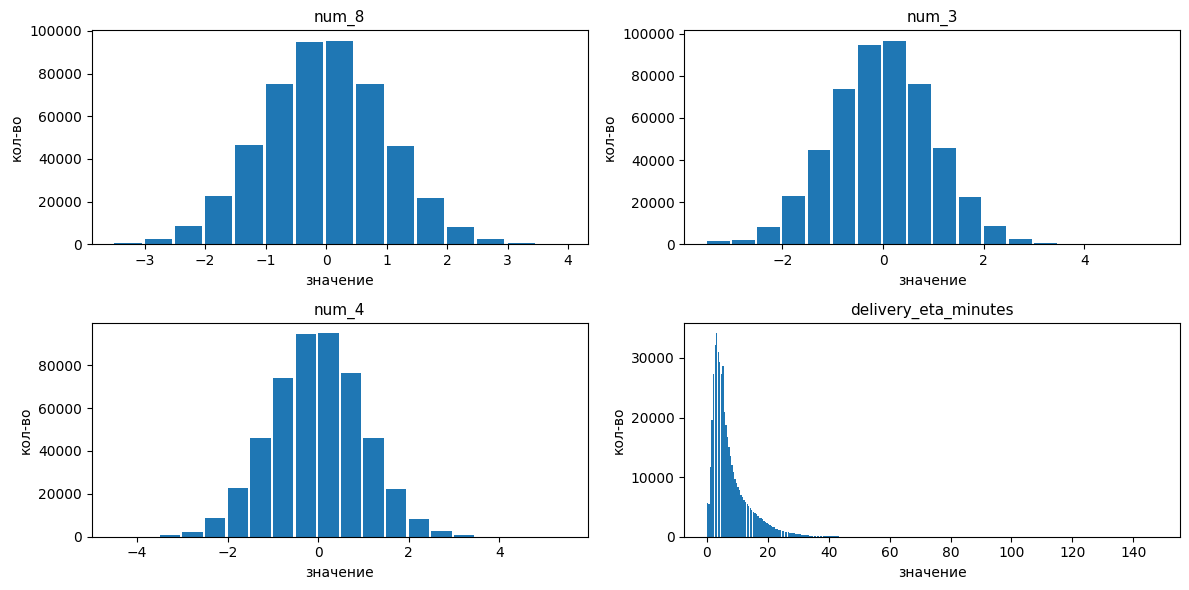

In [224]:
def plot_num_grid(df, cols, step=0.5, ncols=2):
    nrows = -(-len(cols)//ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 3*nrows))
    axes = axes.flatten()
    for i, c in enumerate(cols):
        hist = (df.select(F.floor(F.col(c)/step).cast("int").alias("b"))
                  .groupBy("b").count().orderBy("b").toPandas())
        hist["x"] = hist["b"] * step
        axes[i].bar(hist["x"], hist["count"], width=step*0.9, align="edge")
        axes[i].set_title(c, fontsize=11)
        axes[i].set_xlabel("значение"); axes[i].set_ylabel("кол-во")
    for j in range(len(cols), len(axes)):
        axes[j].axis("off")
    plt.tight_layout()
    plt.show()

plot_num_grid(df, TOP_COLS + [DEM], step=0.5, ncols=2)

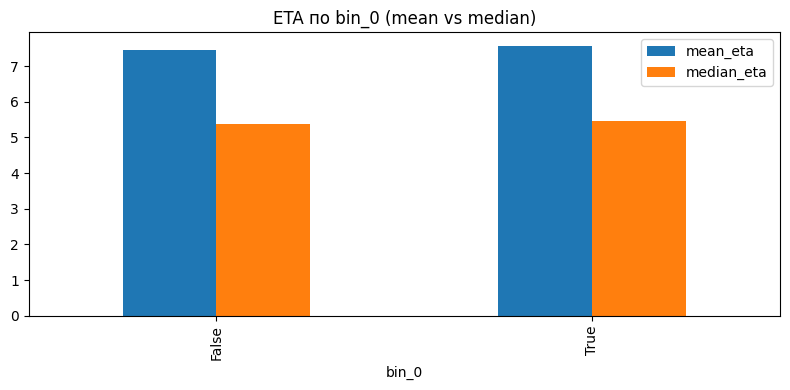

In [225]:
(df.groupBy("bin_0").agg(
    F.mean(DEM).alias("mean_eta"),
    F.expr(f"percentile_approx({DEM}, 0.5)").alias("median_eta"),
    F.count("*").alias("n")
).orderBy("bin_0").toPandas()
 .plot.bar(x="bin_0", y=["mean_eta", "median_eta"], figsize=(8,4),
           title="ETA по bin_0 (mean vs median)"))
plt.tight_layout(); plt.show()

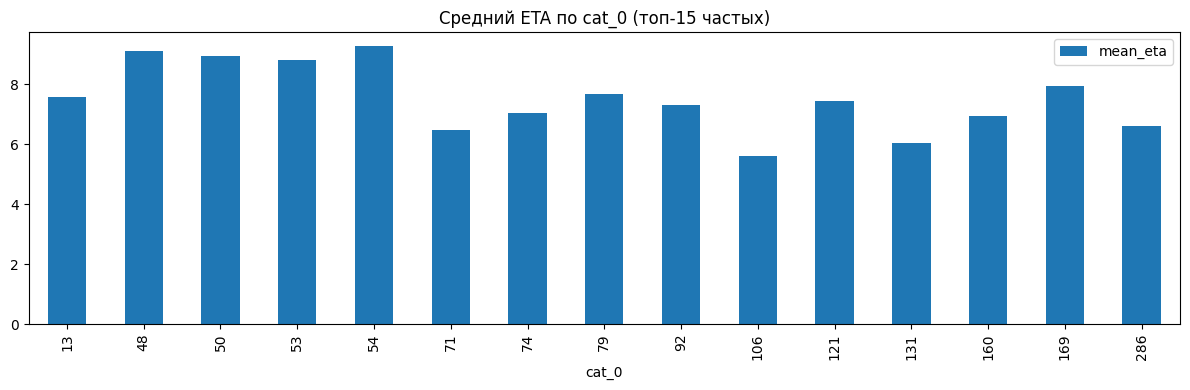

In [226]:
top_cats = (df.groupBy("cat_0").count().orderBy(F.desc("count")).limit(15)
            .select("cat_0").rdd.flatMap(lambda x: x).collect())

(df.filter(F.col("cat_0").isin(top_cats))
   .groupBy("cat_0").agg(
       F.mean(DEM).alias("mean_eta"),
       F.count("*").alias("n")
   ).orderBy("cat_0").toPandas()
   .plot.bar(x="cat_0", y="mean_eta", figsize=(12,4),
             title="Средний ETA по cat_0 (топ-15 частых)"))
plt.tight_layout(); plt.show()

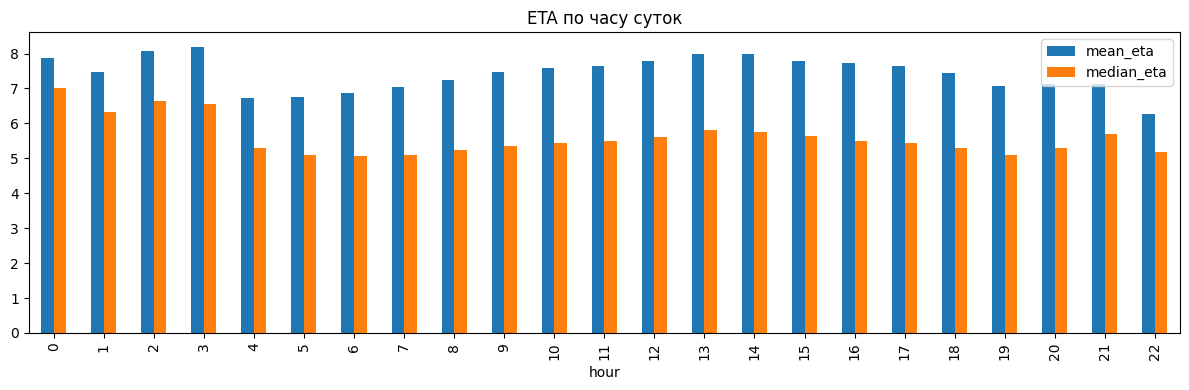

In [227]:
(df.withColumn("hour", F.hour("timestamp"))
   .groupBy("hour").agg(
       F.mean(DEM).alias("mean_eta"),
       F.expr(f"percentile_approx({DEM}, 0.5)").alias("median_eta"),
       F.count("*").alias("n")
   ).orderBy("hour").toPandas()
   .plot.bar(x="hour", y=["mean_eta", "median_eta"], figsize=(12,4),
             title="ETA по часу суток"))
plt.tight_layout(); plt.show()

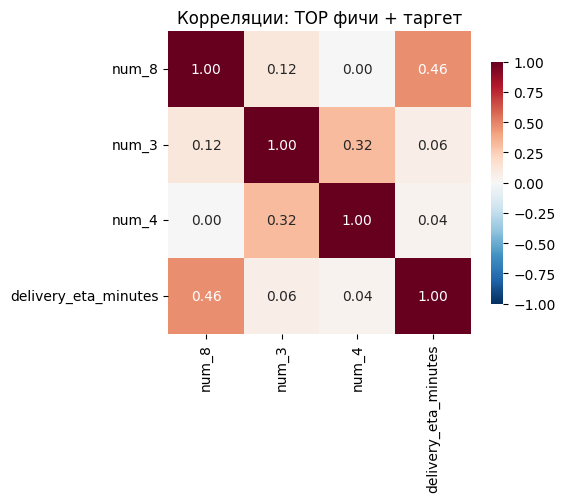

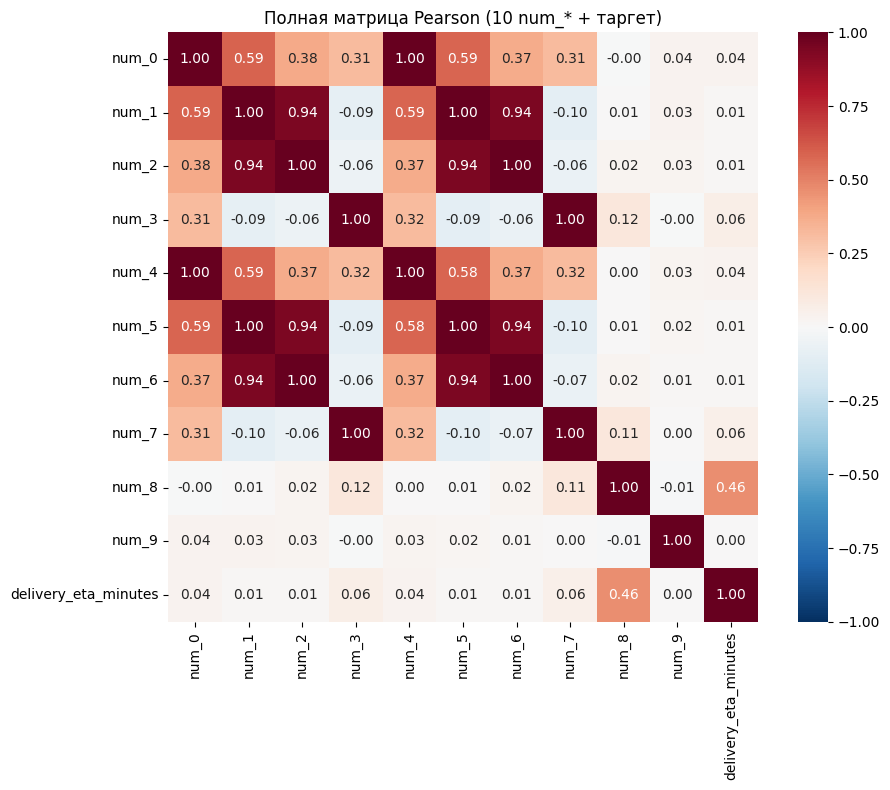

In [230]:
import seaborn as sns

# --- 4×4 для основного текста (TOP_COLS + DEM) ---
sub = pearson.loc[TOP_COLS + [DEM], TOP_COLS + [DEM]]
plt.figure(figsize=(6, 5))
sns.heatmap(sub, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.8})
plt.title("Корреляции: TOP фичи + таргет")
plt.tight_layout(); plt.show()

# --- 11×11 в приложение ---
plt.figure(figsize=(10, 8))
sns.heatmap(pearson, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True)
plt.title("Полная матрица Pearson (10 num_* + таргет)")
plt.tight_layout(); plt.show()

In [231]:
spark.stop()